# IMPORTING LIBRARIES

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats                                                                 
import sklearn
from ucimlrepo import fetch_ucirepo


# LOAD THE DATA 

In [5]:
bank_data = fetch_ucirepo(id=222)                             # Download the Bank Marketing dataset (UCI dataset ID 222)

In [6]:
bank_data

{'data': {'ids': None,
  'features':        age           job   marital  education default  balance housing loan  \
  0       58    management   married   tertiary      no     2143     yes   no   
  1       44    technician    single  secondary      no       29     yes   no   
  2       33  entrepreneur   married  secondary      no        2     yes  yes   
  3       47   blue-collar   married        NaN      no     1506     yes   no   
  4       33           NaN    single        NaN      no        1      no   no   
  ...    ...           ...       ...        ...     ...      ...     ...  ...   
  45206   51    technician   married   tertiary      no      825      no   no   
  45207   71       retired  divorced    primary      no     1729      no   no   
  45208   72       retired   married  secondary      no     5715      no   no   
  45209   57   blue-collar   married  secondary      no      668      no   no   
  45210   37  entrepreneur   married  secondary      no     2971      no  

In [7]:
X = bank_data.data.features.copy()                                    # Store the input features in a DataFrame

In [8]:
X

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,NaN
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,NaN
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,NaN


In [9]:
y = bank_data.data.targets.iloc[:, 0].copy()                                  # Store the target variable separately

In [10]:
y

0         no
1         no
2         no
3         no
4         no
        ... 
45206    yes
45207    yes
45208    yes
45209     no
45210     no
Name: y, Length: 45211, dtype: object

In [11]:
X.head()                                           # Display the first 5 rows

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN


In [12]:
y.head()                                            # Display the first 5 rows

0    no
1    no
2    no
3    no
4    no
Name: y, dtype: object

In [13]:
("Feature dataset shape:", X.shape)                           # Display the number of rows and columns

('Feature dataset shape:', (45211, 16))

In [14]:
("Target dataset shape:", y.shape)                           # Display the number of rows and columns

('Target dataset shape:', (45211,))

In [15]:
X.info()                                                     # Display information about columns, data types and non-null values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
dtypes: int64(7), object(9)
memory usage: 5.5+ MB


In [16]:
X.isnull().sum()                                             # Count missing values in each input column

age                0
job              288
marital            0
education       1857
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
dtype: int64

In [17]:
y.value_counts()                                             # Count how many customers belong to each target class

y
no     39922
yes     5289
Name: count, dtype: int64

In [18]:
y.value_counts(normalize=True) * 100                        # Calculate the percentage of yes and no customers                     

y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64

# VISUALIZE TARGET VARIABLE 

Text(0, 0.5, 'Number of Customers')

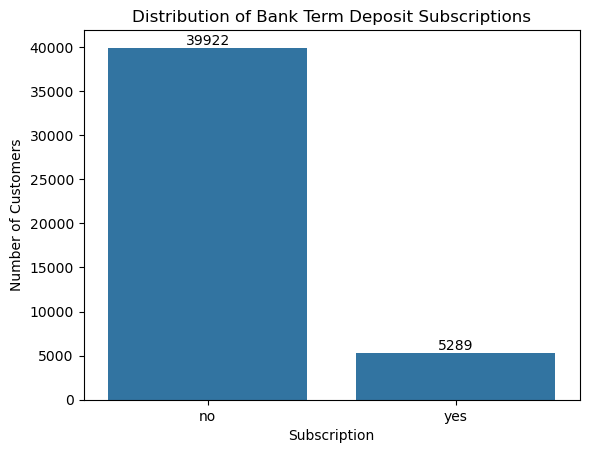

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Combine target values with readable column names
target_df = y.rename("subscription").reset_index(drop=True)

# Create the count plot and store it in ax
ax = sns.countplot(data=target_df.to_frame(), x="subscription")

# Add text on top of each bar
ax.bar_label(ax.containers[0])

# Add chart title and labels
plt.title("Distribution of Bank Term Deposit Subscriptions")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

# PREPROCESS THE DATA 

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline                                                   # Import tools for splitting data and preprocessing
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [21]:
X = X.drop(columns=["duration"], errors="ignore")                                 # Exclude call duration because we want predictions before a call

In [22]:
y = y.astype(str).str.strip().str.lower()                                         # Convert target labels to consistent text

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,                                                              
    y,                                                                    
    test_size=0.20,                                                              # Split the data: 80% for training and 20% for testing                                                            
    random_state=42,                                                              # stratify=y preserves approximately the same class proportions
    stratify=y
)

In [24]:
X_train

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,campaign,pdays,previous,poutcome
24001,36,technician,divorced,secondary,no,861,no,no,telephone,29,aug,2,-1,0,NaN
43409,24,student,single,secondary,no,4126,no,no,cellular,5,apr,4,185,7,failure
20669,44,technician,single,secondary,no,244,yes,no,cellular,12,aug,4,-1,0,NaN
18810,48,unemployed,married,secondary,no,0,no,no,telephone,31,jul,11,-1,0,NaN
23130,38,technician,married,secondary,no,257,no,no,cellular,26,aug,10,-1,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17958,50,blue-collar,married,secondary,no,917,yes,no,cellular,30,jul,2,-1,0,NaN
15941,36,admin.,single,secondary,no,22,yes,no,cellular,22,jul,5,-1,0,NaN
16952,45,blue-collar,married,secondary,no,79,yes,no,cellular,25,jul,1,-1,0,NaN
34781,27,management,single,tertiary,no,2559,yes,no,cellular,6,may,1,-1,0,NaN


In [25]:
X_test

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,campaign,pdays,previous,poutcome
1392,40,blue-collar,married,primary,no,640,yes,yes,NaN,8,may,2,-1,0,NaN
7518,44,technician,married,secondary,no,378,yes,no,NaN,30,may,2,-1,0,NaN
12007,31,services,married,secondary,no,356,yes,no,NaN,20,jun,5,-1,0,NaN
5536,36,blue-collar,married,primary,no,655,yes,no,NaN,23,may,4,-1,0,NaN
29816,34,services,single,secondary,no,1921,yes,no,cellular,4,feb,1,-1,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12636,26,blue-collar,single,secondary,no,-333,no,yes,NaN,4,jul,1,-1,0,NaN
13364,49,services,married,secondary,no,884,yes,no,telephone,8,jul,3,-1,0,NaN
16102,32,entrepreneur,married,tertiary,no,964,yes,no,cellular,22,jul,2,-1,0,NaN
42097,20,student,single,primary,no,0,no,no,cellular,2,nov,4,182,4,failure


In [26]:
y_train

24001     no
43409    yes
20669    yes
18810     no
23130     no
        ... 
17958     no
15941     no
16952     no
34781     no
44229    yes
Name: y, Length: 36168, dtype: object

In [27]:
y_test

1392     no
7518     no
12007    no
5536     no
29816    no
         ..
12636    no
13364    no
16102    no
42097    no
31033    no
Name: y, Length: 9043, dtype: object

In [28]:
numeric_columns = X_train.select_dtypes(
    include=["number"]                                                         # Identify numerical columns, such as age and balance
).columns.tolist()

In [29]:
numeric_columns

['age', 'balance', 'day_of_week', 'campaign', 'pdays', 'previous']

In [30]:
categorical_columns = X_train.select_dtypes(
    exclude=["number"]                                                         # Identify categorical columns, such as job and education
).columns.tolist() 

In [31]:
categorical_columns

['job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'poutcome']

In [32]:
numeric_pipeline = Pipeline([
    # Replace missing numbers with the median
    ("imputer", SimpleImputer(strategy="median")),                            # Prepare numerical columns

    # Scale numbers to comparable ranges
    ("scaler", StandardScaler())
])

In [33]:
numeric_pipeline

,steps,"[('imputer', ...), ('scaler', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [34]:
categorical_pipeline = Pipeline([
    # Replace missing categories with the most common category
    ("imputer", SimpleImputer(strategy="most_frequent")),                    # Prepare categorical columns

    # Convert text categories into numerical columns
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [35]:
categorical_pipeline

,steps,"[('imputer', ...), ('encoder', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,categories,'auto'


In [36]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_columns),                              # Apply the appropriate preprocessing to each column type
    ("cat", categorical_pipeline, categorical_columns)
])

In [37]:
preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [38]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))                                      # Display the sizes of the training and testing sets
print("Numerical features:", len(numeric_columns))
print("Categorical features:", len(categorical_columns))

Training records: 36168
Testing records: 9043
Numerical features: 6
Categorical features: 9


# TRAIN THE BASELINE MODEL 

In [39]:
from sklearn.linear_model import LogisticRegression                           # Import the Logistic Regression algorithm

In [40]:
# Build a Complete Pipeline:
# First preprocess the data, then train the classifier 

baseline_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,                            # Allow enough iterations to converge
        class_weight="balanced",                  # Account for the imbalanced target
        random_state=42
    ))
])

In [41]:
baseline_model.fit(X_train, y_train)                                            # Train the model using the training data

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [42]:
baseline_predictions = baseline_model.predict(X_test)                          # Predict subscription labels for unseen test records

In [43]:
print("First 10 predictions:")                                                # Display a few predicted labels
print(baseline_predictions[:10])

First 10 predictions:
['no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes' 'no' 'no']


In [44]:
print("First 10 actual values:")                                             # Display the corresponding actual labels
print(y_test.iloc[:10].to_numpy())

First 10 actual values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']


# EVALUATE MODEL PERFORMANCE 

In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,                                            # Import Evaluation Functions
    f1_score,
    roc_auc_score,
    classification_report
)

In [46]:
accuracy = accuracy_score(y_test, baseline_predictions)                   # Calculate accuracy

In [47]:
accuracy

0.7622470419108703

In [48]:
precision = precision_score(
    y_test, baseline_predictions,                             # Calculate precision for customers who subscribe
    pos_label="yes", zero_division=0
)

In [49]:
precision

0.268054375531011

In [50]:
recall = recall_score(
    y_test, baseline_predictions,                            # Calculate Recall for Customers Who Subscribe
    pos_label="yes", zero_division=0
)

In [51]:
recall

0.5964083175803403

In [52]:
# Calculate F1-score for the yes class
f1 = f1_score(
    y_test, baseline_predictions,                           # Calculate F1-Score for the Yes Class
    pos_label="yes", zero_division=0
)

In [53]:
f1

0.3698710433763189

In [54]:
yes_column = list(baseline_model.classes_).index("yes")                                 # Get the model's predicted probability of subscription
yes_probabilities = baseline_model.predict_proba(X_test)[:, yes_column]

In [55]:
yes_column

1

In [56]:
yes_probabilities

array([0.17384634, 0.24378722, 0.26109774, ..., 0.35988957, 0.6063607 ,
       0.34611919], shape=(9043,))

In [57]:
roc_auc = roc_auc_score(
    (y_test == "yes").astype(int),                                       # Calculate ROC-AUC using predicted probabilities
    yes_probabilities 
)

In [58]:
roc_auc

0.7517771388461114

In [59]:
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))                                      # Print the evaluation results
print("F1-score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))

Accuracy: 0.7622
Precision: 0.2681
Recall: 0.5964
F1-score: 0.3699
ROC-AUC: 0.7518


In [60]:
print(classification_report(
    y_test,
    baseline_predictions,                                     # Show precision, recall, F1-score, and support for each class  
    zero_division=0
))

              precision    recall  f1-score   support

          no       0.94      0.78      0.85      7985
         yes       0.27      0.60      0.37      1058

    accuracy                           0.76      9043
   macro avg       0.60      0.69      0.61      9043
weighted avg       0.86      0.76      0.80      9043



# VISULAIZE THE CONFUSION MATRIX

Text(0.5, 1.0, 'Confusion Matrix - Logistic Regression')

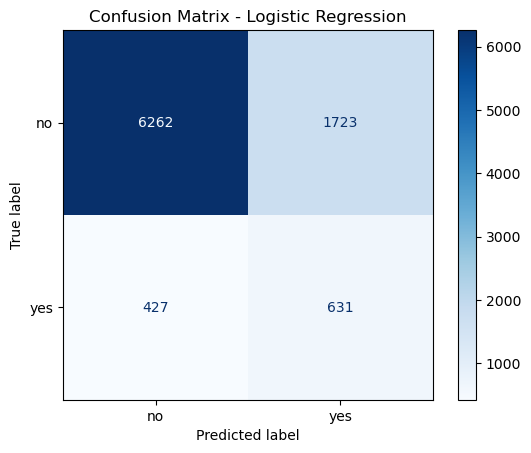

In [61]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay             # Import the confusion matrix function
 
class_labels = ["no", "yes"]                                                     # Keep the class order consistent

cm = confusion_matrix(
    y_test,
    baseline_predictions,                                                        # Compare actual values against predicted values
    labels=class_labels
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,                                                         # Display the confusion matrix as a graph
    display_labels=class_labels
)

display_matrix.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Logistic Regression")                             # Add a title



# PLOT THE ROC CURVE 

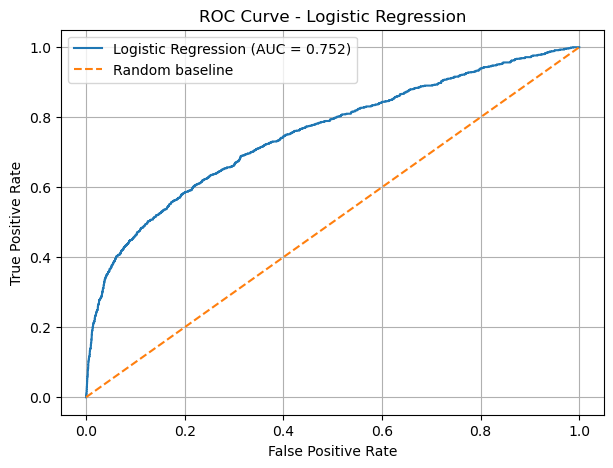

In [62]:
from sklearn.metrics import roc_curve, auc                                     # Import ROC curve calculation tools

fpr, tpr, thresholds = roc_curve(
    (y_test == "yes").astype(int),                                             # Calculate false-positive and true-positive rates
    yes_probabilities
)

roc_area = auc(fpr, tpr)                                                       # Calculate the area under the ROC curve


plt.figure(figsize=(7, 5))                                                     # Plot the ROC curve
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_area:.3f})")


plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")              # Add a diagonal reference line for random ranking


plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")                                               # Label and format the chart
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(True)

# APPLY GRID SEARCH 

In [63]:
# Import GridSearchCV for hyperparameter tuning
from sklearn.model_selection import GridSearchCV

# Define the settings we want to test
parameter_grid = {
    "classifier__C": [0.1, 1, 10]
}

In [64]:
parameter_grid

{'classifier__C': [0.1, 1, 10]}

In [65]:
# Create a grid search that tests each setting using 5-fold CV
grid_search = GridSearchCV(
    estimator=baseline_model,
    param_grid=parameter_grid,
    scoring="f1",       # Optimize F1 for the positive class
    cv=5,               # Use five cross-validation folds
    n_jobs=-1,          # Use available CPU cores
    verbose=1
)

In [66]:
grid_search

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'classifier__C': [0.1, 1, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [67]:
# Train and evaluate each candidate configuration
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 3 candidates, totalling 15 fits


C:\Users\Amaan\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [nan nan nan]
  warnings.warn(


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'classifier__C': [0.1, 1, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [68]:
print("Best parameters:", grid_search.best_params_)                     # Display the best parameter setting

Best parameters: {'classifier__C': 0.1}


In [69]:
print("Best CV F1-score:", round(grid_search.best_score_, 4))          # Display the best mean cross-validation F1-score

Best CV F1-score: nan


In [70]:
for params, score in zip(
    grid_search.cv_results_["params"],
    grid_search.cv_results_["mean_test_score"]                        # Display the mean score for every tested configuration
):
    print(params, "Mean CV F1:", round(score, 4))

{'classifier__C': 0.1} Mean CV F1: nan
{'classifier__C': 1} Mean CV F1: nan
{'classifier__C': 10} Mean CV F1: nan


# FINAL CONFUSION MATRIX 

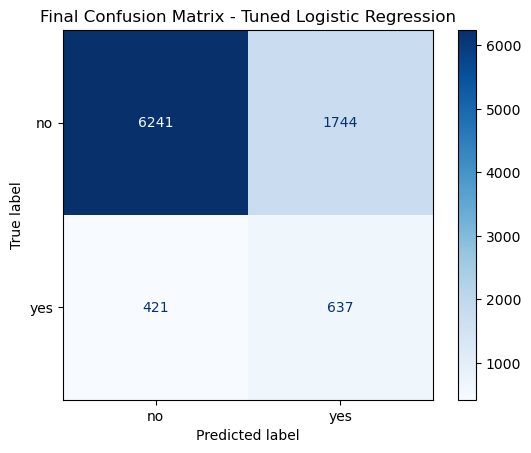

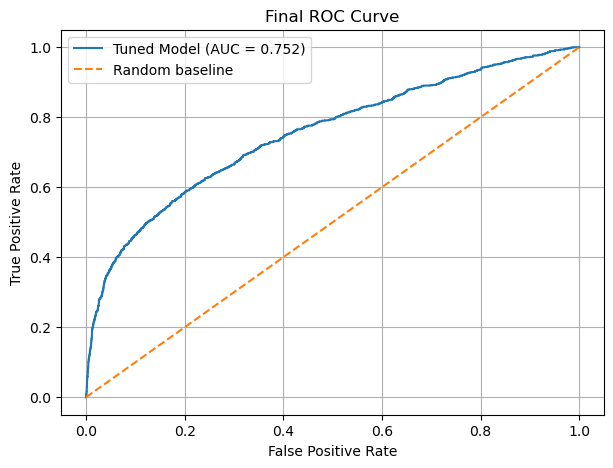

In [71]:
# Create the final confusion matrix

# Get the best model selected by Grid Search

best_model = grid_search.best_estimator_

# Predict the results for the test dataset

final_predictions = best_model.predict(X_test) 

final_cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=["no", "yes"]
)

# Display it
ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["no", "yes"]
).plot(cmap="Blues", values_format="d")

plt.title("Final Confusion Matrix - Tuned Logistic Regression")
plt.show()

final_probabilities = best_model.predict_proba(X_test)[:, yes_column]

# Calculate final ROC curve points
final_fpr, final_tpr, _ = roc_curve(
    (y_test == "yes").astype(int),
    final_probabilities
)

# Calculate the ROC-AUC score

from sklearn.metrics import roc_auc_score

final_auc = roc_auc_score(
(y_test == "yes").astype(int),
final_probabilities
)

# Draw the final ROC curve
plt.figure(figsize=(7, 5))
plt.plot(
    final_fpr,
    final_tpr,
    label=f"Tuned Model (AUC = {final_auc:.3f})"
)

# Draw the random-ranking reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

# EVALUATE THE TUNED MODEL 

In [72]:
# Retrieve the best pipeline found by Grid Search
best_model = grid_search.best_estimator_

# Make predictions on the test set that was held aside
final_predictions = best_model.predict(X_test)

# Calculate the final predicted probabilities
yes_column = list(best_model.classes_).index("yes")
final_probabilities = best_model.predict_proba(X_test)[:, yes_column]

# Calculate final test metrics
final_accuracy = accuracy_score(y_test, final_predictions)

final_precision = precision_score(
    y_test, final_predictions,
    pos_label="yes", zero_division=0
)

final_recall = recall_score(
    y_test, final_predictions,
    pos_label="yes", zero_division=0
)

final_f1 = f1_score(
    y_test, final_predictions,
    pos_label="yes", zero_division=0
)

final_auc = roc_auc_score(
    (y_test == "yes").astype(int),
    final_probabilities
)

# Display the final results
print("FINAL TEST RESULTS")
print("------------------")
print("Accuracy:", round(final_accuracy, 4))
print("Precision:", round(final_precision, 4))
print("Recall:", round(final_recall, 4))
print("F1-score:", round(final_f1, 4))
print("ROC-AUC:", round(final_auc, 4))

# Display a detailed report for both classes
print(classification_report(
    y_test,
    final_predictions,
    zero_division=0
))

FINAL TEST RESULTS
------------------
Accuracy: 0.7606
Precision: 0.2675
Recall: 0.6021
F1-score: 0.3705
ROC-AUC: 0.7522
              precision    recall  f1-score   support

          no       0.94      0.78      0.85      7985
         yes       0.27      0.60      0.37      1058

    accuracy                           0.76      9043
   macro avg       0.60      0.69      0.61      9043
weighted avg       0.86      0.76      0.80      9043



# COMPARE BASELINE AND TUNED PERFORMANCE 

In [73]:
# Store the baseline and tuned scores in a table
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Baseline": [
        accuracy, precision, recall, f1, roc_auc
    ],
    "Tuned Model": [
        final_accuracy, final_precision, final_recall,
        final_f1, final_auc
    ]
})

# Calculate the change in each metric
comparison["Change"] = (
    comparison["Tuned Model"] - comparison["Baseline"]
)

# Display the comparison
print(comparison.round(4))

      Metric  Baseline  Tuned Model  Change
0   Accuracy    0.7622       0.7606 -0.0017
1  Precision    0.2681       0.2675 -0.0005
2     Recall    0.5964       0.6021  0.0057
3   F1-score    0.3699       0.3705  0.0006
4    ROC-AUC    0.7518       0.7522  0.0004


# COMPARE WITH RANDOM FOREST 

In [74]:
# Import the Random Forest algorithm
from sklearn.ensemble import RandomForestClassifier

# Build a pipeline using the same preprocessing
rf_model = Pipeline([
    ("preprocessing", preprocessor),

    # Train a collection of decision trees
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=1
    ))
])

# Define a manageable set of parameters to test
rf_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [10, None],
    "classifier__min_samples_leaf": [1, 5]
}

# Search for a good combination using five-fold CV
rf_search = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Train the candidate models
rf_search.fit(X_train, y_train)

# Display the best Random Forest configuration
print("Best Random Forest parameters:", rf_search.best_params_)

# Display its cross-validation F1-score
print("Random Forest CV F1:", round(rf_search.best_score_, 4))

# Evaluate the selected Random Forest on the test set
rf_best = rf_search.best_estimator_
rf_predictions = rf_best.predict(X_test)

print("Random Forest test F1-score:",
      round(f1_score(
          y_test, rf_predictions,
          pos_label="yes", zero_division=0
      ), 4))

print("Random Forest test ROC-AUC:",
      round(roc_auc_score(
          (y_test == "yes").astype(int),
          rf_best.predict_proba(X_test)[:, list(rf_best.classes_).index("yes")]
      ), 4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits


C:\Users\Amaan\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan]
  warnings.warn(


Best Random Forest parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}
Random Forest CV F1: nan
Random Forest test F1-score: 0.4393
Random Forest test ROC-AUC: 0.7779
